In [ ]:
!pip install -q "transformers>=4.46,<5" datasets accelerate

import torch
print("GPU available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU ONLY - switch to T4 GPU")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 41.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 40.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
GPU available: True
Device: Tesla T4


In [ ]:
CSV_PATH  = "/content/drive/MyDrive/Combined Data.csv"
SAVE_DIR  = "/content/drive/MyDrive/saved_mental_status_bert"

# None = full dataset. Set to 2000 first for a fast test run.
SAMPLE_SIZE = None

In [ ]:
import pandas as pd
import numpy as np
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv(CSV_PATH)
data.dropna(inplace=True)

if 'Unnamed: 0' in data.columns:
    data.drop(columns=['Unnamed: 0'], inplace=True)

print("Rows loaded:", len(data))

before = len(data)
data = data.drop_duplicates(subset='statement').reset_index(drop=True)
print(f"Duplicates removed: {before - len(data)}  ->  {len(data)} unique rows")

if SAMPLE_SIZE is not None:
    data = data.sample(n=SAMPLE_SIZE, random_state=42).reset_index(drop=True)
    print("SMOKE TEST MODE -", len(data), "rows")

data.head()

Rows loaded: 52681
Duplicates removed: 1608  ->  51073 unique rows


,statement,status
0,oh my gosh,Anxiety
1,"trouble sleeping, confused mind, restless hear...",Anxiety
2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety
3,I've shifted my focus to something else but I'...,Anxiety
4,"I'm restless and restless, it's been a month n...",Anxiety


In [ ]:
import re

def clean_statement(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)   # strip URLs
    text = re.sub(r'\s+', ' ', text)                 # collapse whitespace
    return text.strip()

data['statement'] = data['statement'].apply(clean_statement)
data = data[data['statement'].str.strip() != ''].reset_index(drop=True)

print("Rows after cleaning:", len(data))
data['status'].value_counts()

Rows after cleaning: 51072


,count
status,
Normal,16039
Depression,15087
Suicidal,10640
Anxiety,3617
Bipolar,2501
Stress,2293
Personality disorder,895


In [ ]:
label_encoder = LabelEncoder()
data['label'] = label_encoder.fit_transform(data['status'])
print(dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))

{'Anxiety': 0, 'Bipolar': 1, 'Depression': 2, 'Normal': 3, 'Personality disorder': 4, 'Stress': 5, 'Suicidal': 6}


In [ ]:
train_texts, test_texts, train_labels, test_labels = train_test_split(
    data['statement'], data['label'],
    test_size=0.2, random_state=42, stratify=data['label']
)

print("Train rows:", len(train_texts), "| Test rows:", len(test_texts))
print(pd.Series(label_encoder.inverse_transform(test_labels)).value_counts())

Train rows: 40857 | Test rows: 10215
Normal                  3208
Depression              3018
Suicidal                2128
Anxiety                  723
Bipolar                  500
Stress                   459
Personality disorder     179
Name: count, dtype: int64


In [ ]:
classes = np.unique(train_labels)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=train_labels)
weights = weights ** 0.5      # <-- NEW: soften, stops over-correcting toward rare classes
class_weights = torch.tensor(weights, dtype=torch.float)

for cls_name, w in zip(label_encoder.inverse_transform(classes), weights):
    print(f"{cls_name:22s} weight = {w:.3f}")

Anxiety                weight = 1.420
Bipolar                weight = 1.708
Depression             weight = 0.695
Normal                 weight = 0.674
Personality disorder   weight = 2.855
Stress                 weight = 1.784
Suicidal               weight = 0.828


In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

# NEW: check truncation before committing to a long run
lens = [len(tokenizer.encode(t)) for t in train_texts.sample(2000, random_state=42)]
print(f"median {np.median(lens):.0f} | 95th pct {np.percentile(lens,95):.0f} | over 200: {np.mean(np.array(lens)>200)*100:.1f}%")

# cell 10 — tokenize without padding, cap at BERT's real limit
train_encodings = tokenizer(list(train_texts), padding=False, truncation=True, max_length=512)
test_encodings  = tokenizer(list(test_texts),  padding=False, truncation=True, max_length=512)

train_dataset = Dataset.from_dict({
    'input_ids': train_encodings['input_ids'],
    'attention_mask': train_encodings['attention_mask'],
    'labels': train_labels.tolist()
})

test_dataset = Dataset.from_dict({
    'input_ids': test_encodings['input_ids'],
    'attention_mask': test_encodings['attention_mask'],
    'labels': test_labels.tolist()
})

print(train_dataset)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Token indices sequence length is longer than the specified maximum sequence length for this model (578 > 512). Running this sequence through the model will result in indexing errors


median 76 | 95th pct 460 | over 200: 22.2%
Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 40857
})


In [ ]:
from transformers import DataCollatorWithPadding

model = BertForSequenceClassification.from_pretrained(
    'bert-base-uncased', num_labels=len(label_encoder.classes_)
)

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = torch.nn.CrossEntropyLoss(weight=class_weights.to(logits.device))
        loss = loss_fct(logits.view(-1, logits.size(-1)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

training_args = TrainingArguments(
    output_dir="/content/results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=5,
    weight_decay=0.01,
    logging_steps=50,
    lr_scheduler_type="linear",
    warmup_steps=500,
    load_best_model_at_end=True,
    save_total_limit=2,
    fp16=True,
    report_to="none",
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    data_collator=DataCollatorWithPadding(tokenizer),
)

trainer.train()

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss
1,0.454100,0.483440
2,0.340100,0.464799
3,0.251000,0.549387
4,0.144900,0.657881
5,0.155000,0.786184


TrainOutput(global_step=12770, training_loss=0.3236433909661899, metrics={'train_runtime': 5319.5933, 'train_samples_per_second': 38.402, 'train_steps_per_second': 2.401, 'total_flos': 4.56726195830643e+16, 'train_loss': 0.3236433909661899, 'epoch': 5.0})

                      precision    recall  f1-score   support

             Anxiety       0.89      0.89      0.89       723
             Bipolar       0.87      0.82      0.84       500
          Depression       0.83      0.73      0.78      3018
              Normal       0.97      0.95      0.96      3208
Personality disorder       0.65      0.68      0.66       179
              Stress       0.67      0.85      0.75       459
            Suicidal       0.71      0.81      0.75      2128

            accuracy                           0.84     10215
           macro avg       0.80      0.82      0.80     10215
        weighted avg       0.84      0.84      0.84     10215



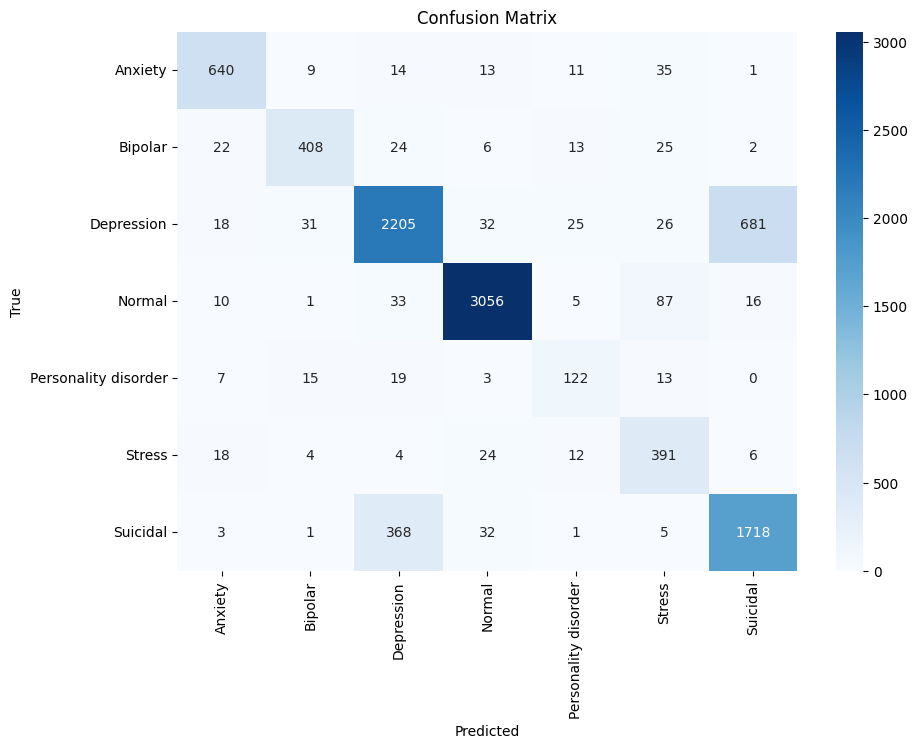

In [ ]:
predictions, labels, _ = trainer.predict(test_dataset)
predicted_labels = np.argmax(predictions, axis=1)

print(classification_report(test_labels, predicted_labels, target_names=label_encoder.classes_))

cm = confusion_matrix(test_labels, predicted_labels)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion Matrix')
plt.show()

In [ ]:
import os, pickle

os.makedirs(SAVE_DIR, exist_ok=True)
trainer.save_model(SAVE_DIR)
tokenizer.save_pretrained(SAVE_DIR)
pickle.dump(label_encoder, open(f"{SAVE_DIR}/label_encoder.pkl", "wb"))

print(os.listdir(SAVE_DIR))

['config.json', 'tokenizer_config.json', 'model.safetensors', 'tokenizer.json', 'training_args.bin', 'label_encoder.pkl', 'special_tokens_map.json', 'vocab.txt']


In [ ]:
def detect_status(text):
    text = clean_statement(text)
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=512).to(model.device)
    model.eval()
    with torch.no_grad():
        outputs = model(**inputs)
    predicted_label = torch.argmax(outputs.logits, dim=1).item()
    return label_encoder.inverse_transform([predicted_label])[0]

sample_texts = [
    "I feel perfectly fine today, nothing to worry about.",
    "I don't think I can keep going, everything feels so hopeless.",
    "Lately, I've been on a high, feeling like I can do anything!",
    "I'm okay today, but sometimes I get really anxious for no reason."
]

for text in sample_texts:
    print(f"Sentence: {text}\nPredicted: {detect_status(text)}\n")

Sentence: I feel perfectly fine today, nothing to worry about.
Predicted: Anxiety

Sentence: I don't think I can keep going, everything feels so hopeless.
Predicted: Normal

Sentence: Lately, I've been on a high, feeling like I can do anything!
Predicted: Normal

Sentence: I'm okay today, but sometimes I get really anxious for no reason.
Predicted: Anxiety



# **Loading The Model For Testing Again**


In [1]:
import re, pickle, torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

SAVE_DIR = "/content/drive/MyDrive/saved_mental_status_bert"
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR).to(device)
tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)
label_encoder = pickle.load(open(f"{SAVE_DIR}/label_encoder.pkl", "rb"))
model.eval()

def clean_statement(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

def detect_status(text):
    text = clean_statement(text)
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
    inputs = {k: v.to(device) for k, v in inputs.items() if k in ('input_ids', 'attention_mask')}
    with torch.no_grad():
        logits = model(**inputs).logits
    return label_encoder.inverse_transform([torch.argmax(logits, dim=1).item()])[0]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [2]:
real_world_tests = {
    "Normal": "Had a pretty solid week honestly. Work was busy but manageable, went for a run twice, and caught up with a couple of old friends over the weekend. Nothing exciting happening but I can't complain.",
    "Anxiety": "I have a presentation tomorrow and I can't stop replaying every way it could go wrong. My heart's been racing on and off all evening, I've checked my slides about ten times, and I know I won't sleep properly tonight.",
    "Depression": "I haven't left my room in three days except to eat. Nothing feels worth doing anymore, even things I used to enjoy. I keep telling myself I'll get up and do something but I just end up back in bed.",
    "Stress": "Between the two deadlines this week and my manager adding another one this morning, I genuinely don't know how I'm going to get it all done. I've barely slept and I feel like I'm one small thing away from losing it.",
    "Suicidal": "Lately I keep thinking everyone would just be better off without me around. I feel like such a burden to my family and I don't see the point in trying anymore.",
}

for true_label, text in real_world_tests.items():
    print(f"Expected: {true_label:12s} | Predicted: {detect_status(text)}")

Expected: Normal       | Predicted: Normal
Expected: Anxiety      | Predicted: Stress
Expected: Depression   | Predicted: Stress
Expected: Stress       | Predicted: Stress
Expected: Suicidal     | Predicted: Stress


In [3]:
import torch.nn.functional as F

def debug_probs(text):
    text = clean_statement(text)
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
    inputs = {k: v.to(device) for k, v in inputs.items() if k in ('input_ids', 'attention_mask')}
    with torch.no_grad():
        probs = F.softmax(model(**inputs).logits, dim=1)[0]
    for name, p in sorted(zip(label_encoder.classes_, probs.tolist()), key=lambda x: -x[1]):
        print(f"  {name:22s} {p:.3f}")

debug_probs(real_world_tests["Suicidal"])

  Stress                 0.875
  Depression             0.065
  Personality disorder   0.037
  Suicidal               0.010
  Normal                 0.008
  Anxiety                0.003
  Bipolar                0.002


In [5]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder as LE2
from sklearn.metrics import classification_report
from datasets import Dataset
from transformers import DataCollatorWithPadding, Trainer
CSV_PATH = "/content/drive/MyDrive/Combined Data.csv"
data = pd.read_csv(CSV_PATH)
data.dropna(inplace=True)
if 'Unnamed: 0' in data.columns: data.drop(columns=['Unnamed: 0'], inplace=True)
data = data.drop_duplicates(subset='statement').reset_index(drop=True)
data['statement'] = data['statement'].apply(clean_statement)
data = data[data['statement'].str.strip() != ''].reset_index(drop=True)

le_check = LE2()
data['label'] = le_check.fit_transform(data['status'])

_, test_texts, _, test_labels = train_test_split(
    data['statement'], data['label'], test_size=0.2, random_state=42, stratify=data['label']
)

test_encodings = tokenizer(list(test_texts), padding=False, truncation=True, max_length=512)
test_dataset = Dataset.from_dict({
    'input_ids': test_encodings['input_ids'],
    'attention_mask': test_encodings['attention_mask'],
    'labels': test_labels.tolist()
})

check_trainer = Trainer(model=model, data_collator=DataCollatorWithPadding(tokenizer))
preds, _, _ = check_trainer.predict(test_dataset)
print(classification_report(test_labels, np.argmax(preds, axis=1), target_names=le_check.classes_))

                      precision    recall  f1-score   support

             Anxiety       0.89      0.89      0.89       723
             Bipolar       0.87      0.82      0.84       500
          Depression       0.83      0.73      0.78      3018
              Normal       0.97      0.95      0.96      3208
Personality disorder       0.65      0.68      0.66       179
              Stress       0.67      0.85      0.75       459
            Suicidal       0.71      0.81      0.75      2128

            accuracy                           0.84     10215
           macro avg       0.80      0.82      0.80     10215
        weighted avg       0.84      0.84      0.84     10215



In [6]:
model.eval()  # rule out stale state from earlier debugging

pos = 0
known_text = test_texts.iloc[pos]
known_true = le_check.inverse_transform([test_labels.iloc[pos]])[0]

batch_style_ids  = test_encodings['input_ids'][pos]
manual_style_ids = tokenizer(clean_statement(known_text), truncation=True, max_length=512)['input_ids']

print("Tokenization matches:", batch_style_ids == manual_style_ids)
print("True label:", known_true)
print("Manual single-example prediction:", detect_status(known_text))

Tokenization matches: True
True label: Depression
Manual single-example prediction: Stress


In [7]:
print("Batch-path prediction for this exact example:", le_check.inverse_transform([np.argmax(preds[pos])])[0])


Batch-path prediction for this exact example: Stress
